In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path as pth

In [5]:
print("Current Working Directory : ", pth.cwd())

Current Working Directory :  /Users/jibanjyotimohanty/Jiban Drive/Project/intelligent-ai-platform/ai-services/document-intelligence/notebooks


In [10]:
possible_paths = [
    pth("../data/raw/bbc-text.csv")
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError("BBC dataset not found. Check the dataset location.")

df = pd.read_csv(DATA_PATH)
print("Dataset Loads Successfully.")
print('Dataset Shape : ', df.shape)

Dataset Loads Successfully.
Dataset Shape :  (2225, 2)


In [22]:
from IPython.display import display
display(df.head())

display(df.tail())

print(df.columns.tolist())
print("Rows : ",df.shape[0])
print("Columns : ", df.shape[1])

,category,text
0,tech,tv future in the hands of viewers with home th...
1,business,worldcom boss left books alone former worldc...
2,sport,tigers wary of farrell gamble leicester say ...
3,sport,yeading face newcastle in fa cup premiership s...
4,entertainment,ocean s twelve raids box office ocean s twelve...


,category,text
2220,business,cars pull down us retail figures us retail sal...
2221,politics,kilroy unveils immigration policy ex-chatshow ...
2222,entertainment,rem announce new glasgow concert us band rem h...
2223,politics,how political squabbles snowball it s become c...
2224,sport,souness delight at euro progress boss graeme s...


['category', 'text']
Rows :  2225
Columns :  2


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   category  2225 non-null   str  
 1   text      2225 non-null   str  
dtypes: str(2)
memory usage: 34.9 KB


In [27]:
df.describe(include="object")

/var/folders/4q/rmb_b9l12v51q3_6z0q6qwj40000gn/T/ipykernel_57001/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,category,text
count,2225,2225
unique,5,2126
top,sport,ocean s twelve raids box office ocean s twelve...
freq,511,2


In [32]:
df.isnull().sum()

category    0
text        0
dtype: int64

In [39]:
df.duplicated().sum()

np.int64(99)

In [41]:
duplicates = df[df.duplicated(keep=False)]
display(duplicates.sort_values(by="text"))

,category,text
1755,tech,2d metal slug offers retro fun like some drill...
137,tech,2d metal slug offers retro fun like some drill...
930,tech,apple attacked over sources row civil libertie...
718,tech,apple attacked over sources row civil libertie...
1060,tech,apple ipod family expands market apple has exp...
...,...,...
1774,tech,warning over tsunami aid website net users are...
956,tech,web radio takes spanish rap global spin the ra...
109,tech,web radio takes spanish rap global spin the ra...
2016,tech,what high-definition will do to dvds first it ...


In [43]:
duplicates_text = df[df.duplicated(subset=['text'], keep=False)]
print("Duplicate Article Records : ", duplicates_text)

category_counts = duplicates_text.groupby("text")['category'].nunique()
print("Articles with conflicting categories : ", (category_counts > 1).sum())

Duplicate Article Records :             category                                               text
4     entertainment  ocean s twelve raids box office ocean s twelve...
13         politics  hague  given up  his pm ambition former conser...
20             tech  security warning over  fbi virus  the us feder...
38         politics  debate needed  on donations cap a cap on donat...
65             tech  broadband in the uk growing fast high-speed ne...
...             ...                                                ...
2206       politics  kennedy questions trust of blair lib dem leade...
2207           tech  california sets fines for spyware the makers o...
2213           tech  progress on new internet domains by early 2005...
2215           tech  junk e-mails on relentless rise spam traffic i...
2217           tech  rings of steel combat net attacks gambling is ...

[198 rows x 2 columns]
Articles with conflicting categories :  0


In [44]:
df_cleaned = df.drop_duplicates(
    subset=['category', 'text'],
    keep='first'
).reset_index(drop=True)

print("Original Dataset Shape : ", df.shape)
print("Cleaned Dataset Shape : ", df_cleaned.shape)
print("Cleaned Duplicates : ", df_cleaned.duplicated().sum())

Original Dataset Shape :  (2225, 2)
Cleaned Dataset Shape :  (2126, 2)
Cleaned Duplicates :  0


In [47]:
print("Missing Values : ", df_cleaned.isnull().sum())
print("Category Distribution : ", df_cleaned['category'].value_counts())

Missing Values :  category    0
text        0
dtype: int64
Category Distribution :  category
sport            504
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64


In [49]:
processedDir = pth('../data/processed')
processedDir.mkdir(parents=True, exist_ok=True)

output_path = processedDir / 'bbc_cleaned.csv'
df_cleaned.to_csv(output_path, index=False)
print("Cleaned Dataset Saved Successfully in : ", output_path)

Cleaned Dataset Saved Successfully in :  ../data/processed/bbc_cleaned.csv


In [50]:
category_counts = df_cleaned['category'].value_counts()
print(category_counts)

category
sport            504
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64


In [53]:
category_percentages = (
    df_cleaned['category'].value_counts(normalize=True) * 100
)

print(category_percentages.round(2))

category
sport            23.71
business         23.66
politics         18.96
entertainment    17.36
tech             16.32
Name: proportion, dtype: float64


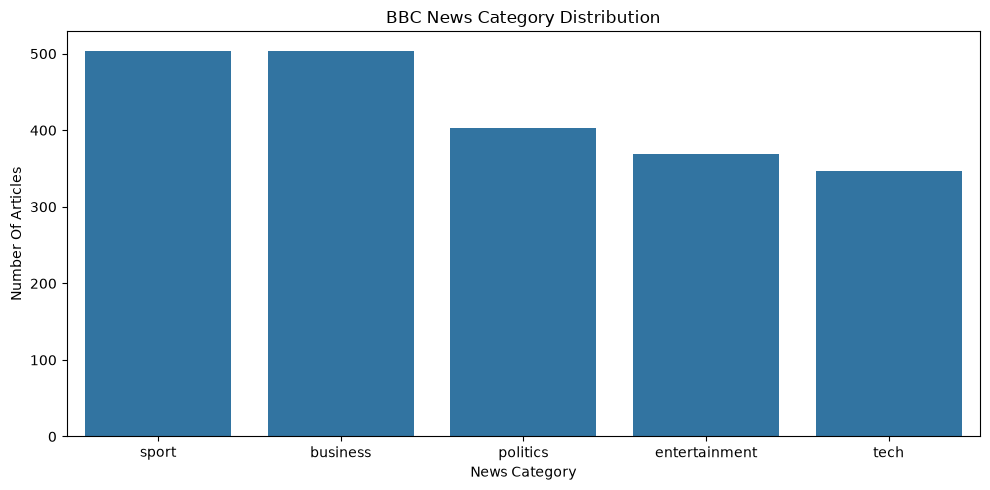

In [56]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_cleaned,
    x='category',
    order=category_counts.index
)

plt.title("BBC News Category Distribution")
plt.xlabel("News Category")
plt.ylabel("Number Of Articles")

plt.tight_layout()
plt.show()

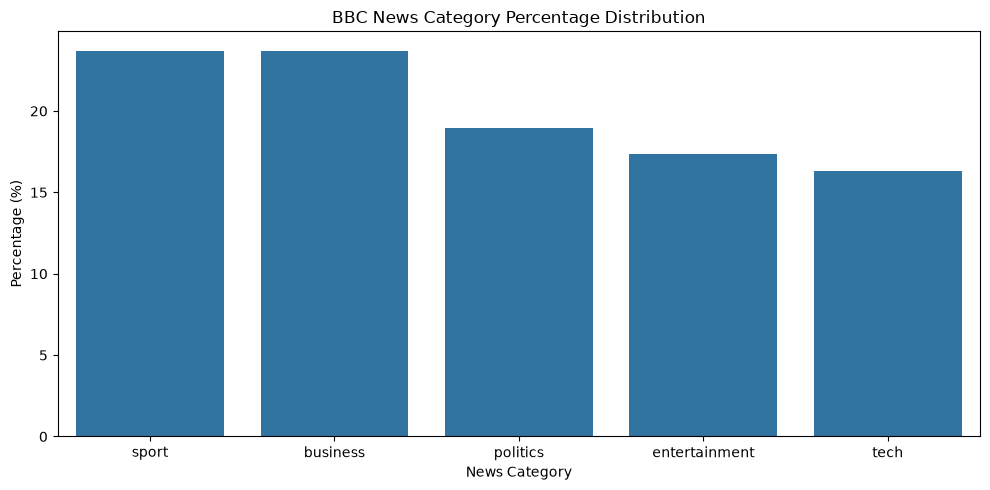

In [57]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x = category_percentages.index,
    y = category_percentages.values
)

plt.title("BBC News Category Percentage Distribution")
plt.xlabel("News Category")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

In [59]:
print("Maximum Category Count : ", category_counts.max())
print("Minimum Category Count : ", category_counts.min())

imbalance_ratio = category_counts.max() / category_counts.min()

print("Imbalance Ratio : ", imbalance_ratio)

Maximum Category Count :  504
Minimum Category Count :  347
Imbalance Ratio :  1.4524495677233429


In [61]:
from sklearn.model_selection import train_test_split

X = df_cleaned["text"]
y = df_cleaned["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [63]:
df_cleaned['word_count'] = df_cleaned['text'].apply(
    lambda text : len(text.split())
)

display(df_cleaned[['category', 'word_count']].head())

,category,word_count
0,tech,737
1,business,300
2,sport,246
3,sport,341
4,entertainment,260


In [64]:
display(df_cleaned['word_count'].describe())

count    2126.000000
mean      390.452023
std       245.118037
min        90.000000
25%       249.000000
50%       336.500000
75%       479.000000
max      4492.000000
Name: word_count, dtype: float64

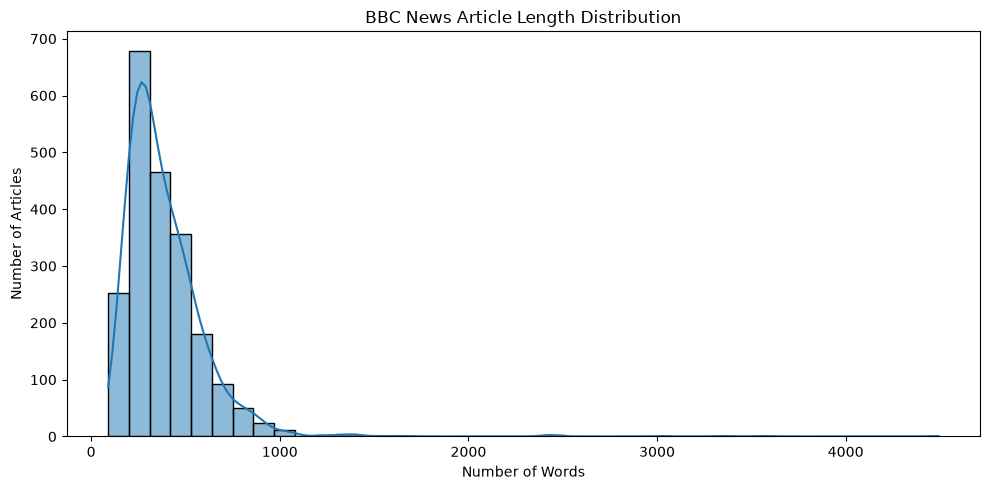

In [69]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_cleaned,
    x='word_count',
    bins=40,
    kde=True
)

plt.title("BBC News Article Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")

plt.tight_layout()
plt.show()

In [71]:
percentiles = df_cleaned["word_count"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Article Length Percentiles:")
print(percentiles)

Article Length Percentiles:
0.50     336.50
0.75     479.00
0.90     628.00
0.95     742.75
0.99    1022.75
Name: word_count, dtype: float64


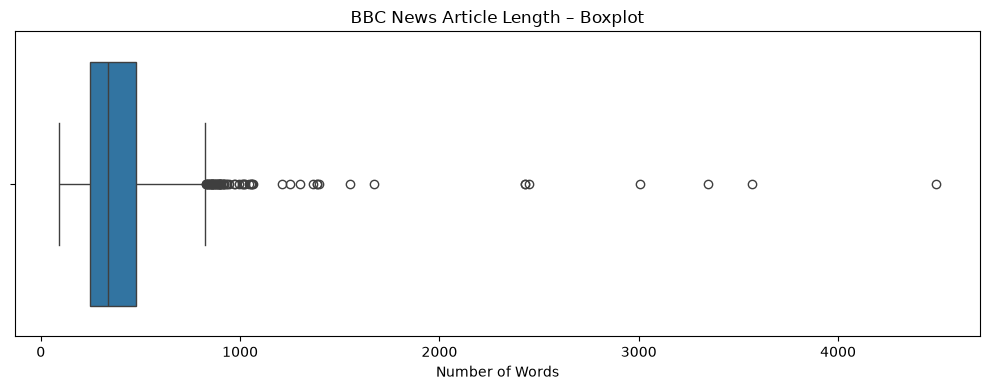

In [72]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df_cleaned["word_count"])

plt.title("BBC News Article Length – Boxplot")
plt.xlabel("Number of Words")

plt.tight_layout()
plt.show()